# Week 7: Dimensionality Reduction

## Project: Moneyball – IPL Player Valuation

### Objectives
1. Identify relevant numerical features from IPL auction and player performance datasets.
2. Standardize selected features before applying Principal Component Analysis (PCA).
3. Apply PCA to reduce the dimensionality of the selected data.
4. Visualize explained variance using graphs.
5. Interpret the results in the context of IPL player valuation.

### Expected Outcome
Understand how dimensionality reduction can simplify player-performance data while retaining important patterns for further analysis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
import os

data_folder = r"D:\DSD\College\DSV\Project\archive\moneyball\datasets"

auction = pd.read_excel(os.path.join(data_folder, "Auction.xlsx"))
batsmen = pd.read_excel(os.path.join(data_folder, "Top_100_batsman.xlsx"))
bowlers = pd.read_excel(os.path.join(data_folder, "Top_100_bowlers.xlsx"))
matches = pd.read_csv(os.path.join(data_folder, "matches.csv"))

print("All four datasets loaded successfully!")

All four datasets loaded successfully!


In [3]:
print("AUCTION DATASET")
print(auction.columns.tolist())

print("\nBATSMEN DATASET")
print(batsmen.columns.tolist())

print("\nBOWLERS DATASET")
print(bowlers.columns.tolist())

print("\nMATCHES DATASET")
print(matches.columns.tolist())

AUCTION DATASET
['TEAM', 'PLAYER', 'TYPE', 'PRICE(In crore Indian Rupees) ', 'YEAR']

BATSMEN DATASET
['POS', 'PLAYER', 'Mat', 'Inns', 'NO', 'Runs', 'HS', 'Avg', 'BF', 'SR', 100, 50, '4s', '6s']

BOWLERS DATASET
['POS', 'PLAYER', 'Mat', 'Inns', 'Ov', 'Runs', 'Wkts', 'BBI', 'Avg', 'Econ', 'SR', '4w', '5w']

MATCHES DATASET
['id', 'season', 'city', 'date', 'team1', 'team2', 'toss_winner', 'toss_decision', 'result', 'dl_applied', 'winner', 'win_by_runs', 'win_by_wickets', 'player_of_match', 'venue', 'umpire1', 'umpire2', 'umpire3']


In [4]:
print("AUCTION NUMERICAL FEATURES")
print(auction.select_dtypes(include=np.number).columns.tolist())

print("\nBATSMEN NUMERICAL FEATURES")
print(batsmen.select_dtypes(include=np.number).columns.tolist())

print("\nBOWLERS NUMERICAL FEATURES")
print(bowlers.select_dtypes(include=np.number).columns.tolist())

AUCTION NUMERICAL FEATURES
['PRICE(In crore Indian Rupees) ', 'YEAR']

BATSMEN NUMERICAL FEATURES
['POS', 'Mat', 'Inns', 'NO', 'Runs', 'Avg', 'BF', 'SR', 100, 50, '4s', '6s']

BOWLERS NUMERICAL FEATURES
['POS', 'Mat', 'Inns', 'Ov', 'Runs', 'Wkts', 'BBI', 'Avg', 'Econ', 'SR', '4w', '5w']


In [5]:
# Select relevant batting performance features
batting_features = batsmen[
    ['Mat', 'Inns', 'NO', 'Runs', 'Avg', 'BF', 'SR']
].copy()

# Select relevant bowling performance features
bowling_features = bowlers[
    ['Mat', 'Inns', 'Ov', 'Runs', 'Wkts', 'Avg', 'Econ', 'SR']
].copy()

print("Batting features selected:", batting_features.shape)
print("Bowling features selected:", bowling_features.shape)

print("\nBatting data preview:")
display(batting_features.head())

print("\nBowling data preview:")
display(bowling_features.head())

Batting features selected: (100, 7)
Bowling features selected: (100, 8)

Batting data preview:


,Mat,Inns,NO,Runs,Avg,BF,SR
0,177,169,26,5412,37.84,4112,131.61
1,193,189,28,5368,33.34,3914,137.14
2,188,183,28,4898,31.60,3744,130.82
3,126,126,17,4706,43.17,3305,142.39
4,159,158,21,4579,33.42,3669,124.80



Bowling data preview:


,Mat,Inns,Ov,Runs,Wkts,Avg,Econ,SR
0,122,122,471.1,3366,170,19.80,7.14,16.62
1,147,147,516.5,3799,157,24.19,7.35,19.75
2,160,157,562.2,3967,150,26.44,7.05,22.49
3,157,156,520.4,4072,150,27.14,7.82,20.82
4,134,131,431.0,3617,147,24.60,8.39,17.59


In [6]:
# Check missing values
print("Missing values in batting features:")
print(batting_features.isnull().sum())

print("\nMissing values in bowling features:")
print(bowling_features.isnull().sum())

# Fill missing values with column medians
batting_features = batting_features.fillna(
    batting_features.median()
)

bowling_features = bowling_features.fillna(
    bowling_features.median()
)

print("\nMissing values handled successfully!")

print("Remaining batting missing values:",
      batting_features.isnull().sum().sum())

print("Remaining bowling missing values:",
      bowling_features.isnull().sum().sum())

Missing values in batting features:
Mat     0
Inns    0
NO      0
Runs    0
Avg     0
BF      0
SR      0
dtype: int64

Missing values in bowling features:
Mat     0
Inns    0
Ov      0
Runs    0
Wkts    0
Avg     0
Econ    0
SR      0
dtype: int64

Missing values handled successfully!
Remaining batting missing values: 0
Remaining bowling missing values: 0


In [7]:
# Standardize batting features
batting_scaler = StandardScaler()
batting_scaled = batting_scaler.fit_transform(batting_features)

# Standardize bowling features
bowling_scaler = StandardScaler()
bowling_scaled = bowling_scaler.fit_transform(bowling_features)

print("Batting standardized shape:", batting_scaled.shape)
print("Bowling standardized shape:", bowling_scaled.shape)

print("\nStandardization completed successfully!")

Batting standardized shape: (100, 7)
Bowling standardized shape: (100, 8)

Standardization completed successfully!


In [8]:
# Apply PCA to batting data
pca_batting = PCA()
batting_pca = pca_batting.fit_transform(batting_scaled)

# Display explained variance
batting_variance = pca_batting.explained_variance_ratio_

print("Explained variance ratio:")
print(batting_variance)

print("\nTotal variance explained:",
      round(batting_variance.sum() * 100, 2), "%")

print("\nBatting PCA shape:", batting_pca.shape)

Explained variance ratio:
[5.98981082e-01 1.89605777e-01 1.30727206e-01 7.46172457e-02
 4.37808085e-03 1.31341227e-03 3.77196795e-04]

Total variance explained: 100.0 %

Batting PCA shape: (100, 7)


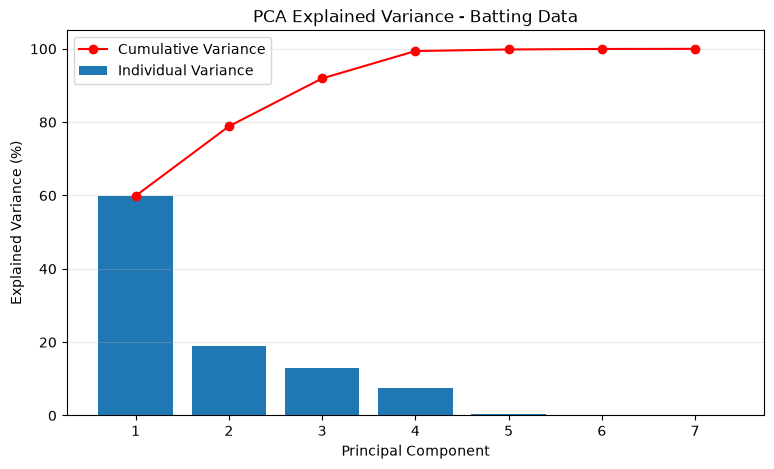

In [9]:
# Calculate cumulative explained variance
cumulative_variance = np.cumsum(batting_variance)

# Plot explained variance
plt.figure(figsize=(9, 5))

plt.bar(
    range(1, len(batting_variance) + 1),
    batting_variance * 100,
    label="Individual Variance"
)

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance * 100,
    marker="o",
    color="red",
    label="Cumulative Variance"
)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance (%)")
plt.title("PCA Explained Variance - Batting Data")
plt.xticks(range(1, len(batting_variance) + 1))
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

In [10]:
# Calculate the number of components needed for 90% variance
cumulative_variance = np.cumsum(batting_variance)

n_components = np.argmax(cumulative_variance >= 0.90) + 1

print("Components needed for 90% variance:", n_components)
print(
    "Cumulative variance explained:",
    round(cumulative_variance[n_components - 1] * 100, 2),
    "%"
)

Components needed for 90% variance: 3
Cumulative variance explained: 91.93 %


In [11]:
# Apply PCA with the selected number of components
pca_batting_reduced = PCA(n_components=n_components)

batting_reduced = pca_batting_reduced.fit_transform(
    batting_scaled
)

# Convert the result into a DataFrame
batting_pca_df = pd.DataFrame(
    batting_reduced,
    columns=[
        f"PC{i+1}" for i in range(n_components)
    ]
)

print("Original number of features:", batting_features.shape[1])
print("Reduced number of features:", batting_pca_df.shape[1])

print("\nReduced batting dataset:")
display(batting_pca_df.head())

Original number of features: 7
Reduced number of features: 3

Reduced batting dataset:


,PC1,PC2,PC3
0,5.267717,0.767217,-0.907603
1,5.506525,0.287599,-0.187589
2,5.057102,-0.203633,-0.393114
3,3.512361,2.234194,-0.647651
4,4.146552,0.100012,-1.125418


In [12]:
# Apply PCA to bowling data
pca_bowling = PCA()
bowling_pca = pca_bowling.fit_transform(bowling_scaled)

# Calculate explained variance
bowling_variance = pca_bowling.explained_variance_ratio_

print("Bowling explained variance ratio:")
print(bowling_variance)

print(
    "\nTotal variance explained:",
    round(bowling_variance.sum() * 100, 2),
    "%"
)

print("Bowling PCA shape:", bowling_pca.shape)

Bowling explained variance ratio:
[5.79868823e-01 2.54327311e-01 1.29550210e-01 3.24661574e-02
 2.46219441e-03 7.35513218e-04 3.57614671e-04 2.32177276e-04]

Total variance explained: 100.0 %
Bowling PCA shape: (100, 8)


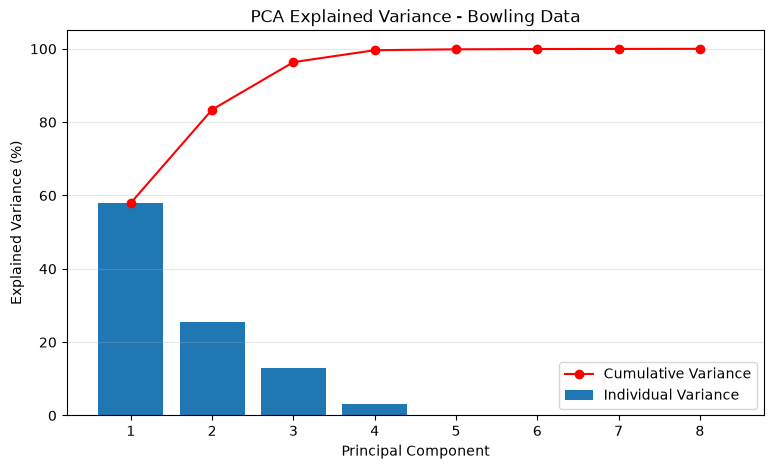

In [13]:
# Calculate cumulative explained variance
bowling_cumulative_variance = np.cumsum(bowling_variance)

# Plot explained variance
plt.figure(figsize=(9, 5))

plt.bar(
    range(1, len(bowling_variance) + 1),
    bowling_variance * 100,
    label="Individual Variance"
)

plt.plot(
    range(1, len(bowling_cumulative_variance) + 1),
    bowling_cumulative_variance * 100,
    marker="o",
    color="red",
    label="Cumulative Variance"
)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance (%)")
plt.title("PCA Explained Variance - Bowling Data")
plt.xticks(range(1, len(bowling_variance) + 1))
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

In [14]:
# Calculate cumulative explained variance
bowling_cumulative_variance = np.cumsum(bowling_variance)

# Find components needed for 90% variance
n_bowling_components = (
    np.argmax(bowling_cumulative_variance >= 0.90) + 1
)

print(
    "Bowling components needed for 90% variance:",
    n_bowling_components
)

print(
    "Cumulative variance explained:",
    round(
        bowling_cumulative_variance[
            n_bowling_components - 1
        ] * 100,
        2
    ),
    "%"
)

Bowling components needed for 90% variance: 3
Cumulative variance explained: 96.37 %


In [15]:
# Apply PCA with the selected number of components
pca_bowling_reduced = PCA(
    n_components=n_bowling_components
)

bowling_reduced = pca_bowling_reduced.fit_transform(
    bowling_scaled
)

# Convert results into a DataFrame
bowling_pca_df = pd.DataFrame(
    bowling_reduced,
    columns=[
        f"PC{i+1}"
        for i in range(n_bowling_components)
    ]
)

print("Original number of features:", bowling_features.shape[1])
print("Reduced number of features:", bowling_pca_df.shape[1])

print("\nReduced bowling dataset:")
display(bowling_pca_df.head())

Original number of features: 8
Reduced number of features: 3

Reduced bowling dataset:


,PC1,PC2,PC3
0,4.824181,-2.151120,-0.383288
1,5.607080,-0.860743,-0.092888
2,6.103059,-0.089085,-0.634097
3,5.802877,-0.155483,0.645536
4,4.500594,-1.021062,1.526580


In [16]:
# Compare original and reduced feature counts
comparison = pd.DataFrame({
    "Dataset": ["Batting", "Bowling"],
    "Original Features": [
        batting_features.shape[1],
        bowling_features.shape[1]
    ],
    "Reduced Components": [
        batting_pca_df.shape[1],
        bowling_pca_df.shape[1]
    ]
})

comparison["Features Reduced"] = (
    comparison["Original Features"]
    - comparison["Reduced Components"]
)

display(comparison)

,Dataset,Original Features,Reduced Components,Features Reduced
0,Batting,7,3,4
1,Bowling,8,3,5


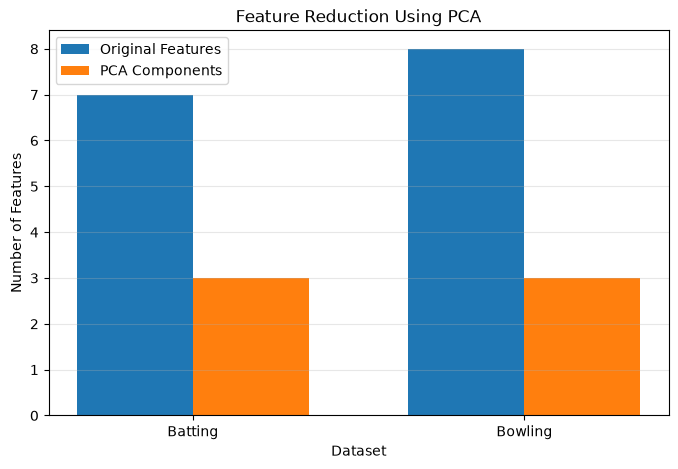

In [17]:
# Plot original vs reduced feature counts
x = np.arange(len(comparison["Dataset"]))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    x - width / 2,
    comparison["Original Features"],
    width,
    label="Original Features"
)

plt.bar(
    x + width / 2,
    comparison["Reduced Components"],
    width,
    label="PCA Components"
)

plt.xlabel("Dataset")
plt.ylabel("Number of Features")
plt.title("Feature Reduction Using PCA")
plt.xticks(x, comparison["Dataset"])
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

## Results and Key Findings

### 1. Feature Selection
Selected numerical batting and bowling performance features for separate PCA analyses.

### 2. Data Standardization
Applied StandardScaler to standardize the selected features before PCA.

### 3. Dimensionality Reduction
Applied Principal Component Analysis (PCA) separately to batting and bowling datasets.

### 4. Explained Variance
Visualized individual and cumulative explained variance to determine the number of components required to retain at least 90% of the variance.

### 5. Comparison
Compared the original feature counts with the reduced component counts to understand the effect of dimensionality reduction.

### Conclusion
PCA provided a way to represent batting and bowling statistics using principal components while retaining a selected proportion of the variance. The results can support further exploratory analysis, but additional analysis is required before drawing conclusions about player valuation.

In [18]:
# Validate reduced batting data
print("BATTING PCA VALIDATION")
print("Shape:", batting_pca_df.shape)
print("Missing values:", batting_pca_df.isnull().sum().sum())
print("Infinite values:", np.isinf(batting_pca_df.to_numpy()).sum())

# Validate reduced bowling data
print("\nBOWLING PCA VALIDATION")
print("Shape:", bowling_pca_df.shape)
print("Missing values:", bowling_pca_df.isnull().sum().sum())
print("Infinite values:", np.isinf(bowling_pca_df.to_numpy()).sum())

print("\nWeek 7 PCA validation completed!")

BATTING PCA VALIDATION
Shape: (100, 3)
Missing values: 0
Infinite values: 0

BOWLING PCA VALIDATION
Shape: (100, 3)
Missing values: 0
Infinite values: 0

Week 7 PCA validation completed!
